In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

from src.auxiliares import dataframe_coeficientes
from src.config import DADOS_LIMPOS
from src.graficos import plot_coeficientes, plot_comparar_metricas_modelos
from src.models import RANDOM_STATE
from src.models import (
    grid_search_cv_classificador,
    treinar_e_validar_modelo_classificacao,
    organiza_resultados,
)

sns.set_theme(palette="bright")

In [2]:
df = pd.read_parquet(DADOS_LIMPOS)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [3]:
X = df.drop(columns=["Species"])
y = df["Species"]

le = LabelEncoder()

y = le.fit_transform(y)

In [4]:
y[:5]

array([0, 0, 0, 0, 0])

In [5]:
le.classes_

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [6]:
le.inverse_transform([0, 1, 2])

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [7]:
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

In [8]:
preprocessamento = Pipeline([("Scaler", StandardScaler())])

In [9]:
classificadores = {
    "DummyClassifier": {
        "preprocessor": None,
        "classificador": DummyClassifier(strategy="stratified")
    },
    
    "LogisticRegression": {
        "preprocessor": preprocessamento,
        "classificador": LogisticRegression()
    },
}

In [10]:
resultados = {
    nome_modelo: treinar_e_validar_modelo_classificacao(
        X, y, kf, **classificador, multi_class=True
    )

    for nome_modelo, classificador in classificadores.items()
}

df_resultados = organiza_resultados(resultados)

df_resultados

,model,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1_weighted,test_precision_weighted,test_recall_weighted,test_roc_auc_ovr,test_average_precision,time_seconds
0,DummyClassifier,0.00282,0.02449,0.36,0.356618,0.355111,0.351729,0.36,0.531974,0.35562,0.02731
1,DummyClassifier,0.000921,0.011303,0.42,0.421569,0.418621,0.427578,0.42,0.579731,0.385831,0.012224
2,DummyClassifier,0.000895,0.01209,0.38,0.379902,0.379191,0.38,0.38,0.580808,0.381492,0.012985
3,LogisticRegression,0.029506,0.039331,1.0,1.0,1.0,1.0,1.0,1.0,0.7713,0.068837
4,LogisticRegression,0.015161,0.024778,0.92,0.919118,0.92,0.92,0.92,0.995172,0.762167,0.039938
5,LogisticRegression,0.009458,0.014974,0.94,0.941176,0.939948,0.940972,0.94,0.997623,0.842977,0.024432


In [12]:
df_resultados.groupby("model").mean().sort_values("test_accuracy")

,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1_weighted,test_precision_weighted,test_recall_weighted,test_roc_auc_ovr,test_average_precision,time_seconds
model,,,,,,,,,,
DummyClassifier,0.001546,0.015961,0.386667,0.386029,0.384308,0.386436,0.386667,0.564171,0.374314,0.017506
LogisticRegression,0.018042,0.026361,0.953333,0.953431,0.953316,0.953657,0.953333,0.997599,0.792148,0.044403


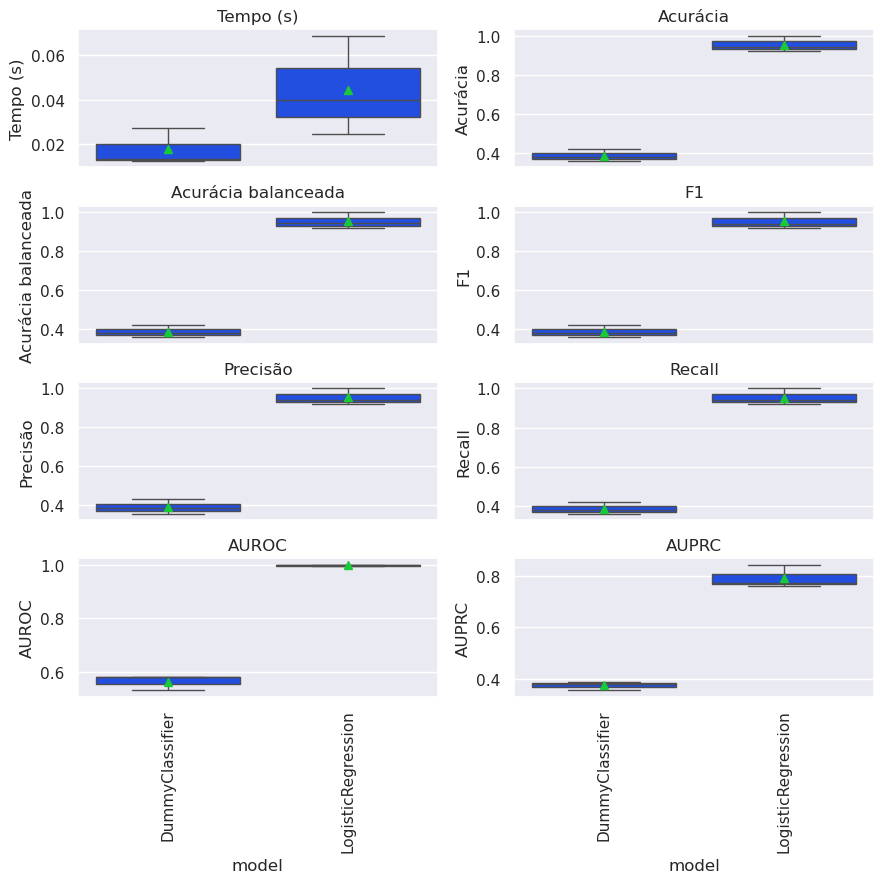

In [13]:
plot_comparar_metricas_modelos(df_resultados, multi_class=True)

In [14]:
param_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__penalty": ["l1", "l2", None],
    "clf__class_weight": [None, "balanced"]
}

In [15]:
clf = LogisticRegression(solver="saga")

grid_search = grid_search_cv_classificador(
    clf, param_grid, kf, preprocessamento, refit_metric="accuracy", multi_class=True
)

grid_search

GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('Scaler',
                                                         StandardScaler())])),
                                       ('clf',
                                        LogisticRegression(solver='saga'))]),
             n_jobs=-1,
             param_grid={'clf__C': [0.1, 1, 10, 100],
                         'clf__class_weight': [None, 'balanced'],
                         'clf__penalty': ['l1', 'l2', None]},
             refit='accuracy',
             scoring=['accuracy', 'balanced_accuracy', 'f1_weighted',
                      'precision_weighted', 'recall_weighted', 'roc_auc_ovr',
                      'average_precision'],
             verbose=1)

In [16]:
grid_search.fit(X, y)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1208: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1208: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1208: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/home/hilario/anaconda3/envs/MachineLearning/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the c

GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        Pipeline(steps=[('Scaler',
                                                         StandardScaler())])),
                                       ('clf',
                                        LogisticRegression(solver='saga'))]),
             n_jobs=-1,
             param_grid={'clf__C': [0.1, 1, 10, 100],
                         'clf__class_weight': [None, 'balanced'],
                         'clf__penalty': ['l1', 'l2', None]},
             refit='accuracy',
             scoring=['accuracy', 'balanced_accuracy', 'f1_weighted',
                      'precision_weighted', 'recall_weighted', 'roc_auc_ovr',
                      'average_precision'],
             verbose=1)

In [17]:
grid_search.best_params_

{'clf__C': 100, 'clf__class_weight': 'balanced', 'clf__penalty': None}

In [18]:
grid_search.best_score_

0.9733333333333333

In [19]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('Scaler', StandardScaler())])),
                ('clf',
                 LogisticRegression(C=100, class_weight='balanced',
                                    penalty=None, solver='saga'))])

In [ ]:
grid_search.best_estimator_["preprocessor"].get_feature_names_out()

array(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'],
      dtype=object)

In [21]:
grid_search.best_estimator_["clf"].coef_

array([[-2.89669954,  2.65055236, -4.88600899, -4.64370616],
       [ 2.14266853, -0.51713681, -2.28497989, -1.85082199],
       [ 0.75403102, -2.13341555,  7.17098888,  6.49452815]])

In [22]:
grid_search.best_estimator_["clf"].classes_

array([0, 1, 2])

Em uma **classificação multiclasse** utilizando regressão logística na abordagem **multinomial**, um único modelo é ajustado para prever todas as classes simultaneamente. Nesse modelo multinomial, são gerados múltiplos conjuntos de coeficientes, um para cada classe, que são usados para calcular as probabilidades relativas entre todas as classes.

1. **Vários arrays para várias classes**: Em problemas de classificação multiclasse, como há mais de duas classes, a regressão logística multinomial retorna um conjunto de coeficientes para cada classe. Cada array em `coef_` corresponde à relação entre as features e a probabilidade de uma classe específica ser a previsão correta, levando em consideração as outras classes simultaneamente.

2. **Forma de `coef_`**:
   - Se houver `n_features` features e `n_classes` classes, `coef_` terá a forma `(n_classes, n_features)`. Cada linha da matriz `coef_` representa um conjunto de coeficientes para uma classe específica, enquanto cada coluna se refere ao peso de uma feature para essa classe.

3. **Exemplo de interpretação**: Se `coef_` retorna uma matriz de coeficientes, cada linha dessa matriz corresponde à influência das features para uma classe específica. Os coeficientes positivos indicam que o aumento no valor de uma feature aumenta a probabilidade de previsão da classe correspondente. Coeficientes negativos indicam que o aumento no valor da feature diminui essa probabilidade. A magnitude do coeficiente reflete a força da influência de uma feature sobre a classe alvo.

4. **Importância dos coeficientes**:
   - **Coeficiente positivo**: Um coeficiente positivo significa que, à medida que o valor da feature aumenta, a probabilidade da classe associada a esse conjunto de coeficientes ser prevista também aumenta.
   - **Coeficiente negativo**: Um coeficiente negativo indica que o aumento no valor da feature reduz a probabilidade de a classe associada ser prevista.
   - **Magnitude**: A magnitude dos coeficientes reflete a força da relação entre a feature e a classe correspondente.


In [27]:
coefs = dataframe_coeficientes(
    grid_search.best_estimator_["clf"].coef_[2],
    grid_search.best_estimator_["preprocessor"].get_feature_names_out()
)

coefs

,coeficiente
SepalWidthCm,-2.133416
SepalLengthCm,0.754031
PetalWidthCm,6.494528
PetalLengthCm,7.170989


In [29]:
X_scaled = grid_search.best_estimator_["preprocessor"].transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns = grid_search.best_estimator_["preprocessor"].get_feature_names_out()
)

df_scaled = pd.concat([X_scaled, pd.Series(le.inverse_transform(y), name= "Species")], axis=1)

df_scaled.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,-0.900681,1.032057,-1.341272,-1.312977,Iris-setosa
1,-1.143017,-0.124958,-1.341272,-1.312977,Iris-setosa
2,-1.385353,0.337848,-1.398138,-1.312977,Iris-setosa
3,-1.506521,0.106445,-1.284407,-1.312977,Iris-setosa
4,-1.021849,1.263460,-1.341272,-1.312977,Iris-setosa


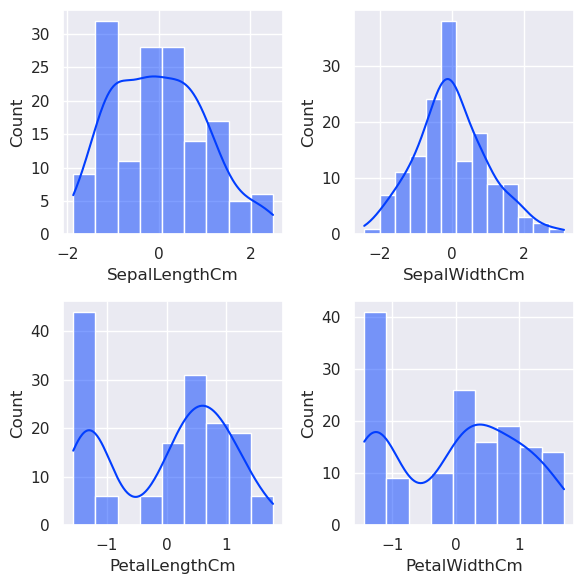

In [30]:
fig, axs = plt.subplots(2, 2, figsize=(6, 6))

for ax, coluna in zip(axs.flatten(), X_scaled.columns):
    sns.histplot(x=coluna, data=df_scaled, ax=ax, kde=True)

plt.tight_layout()
plt.show()

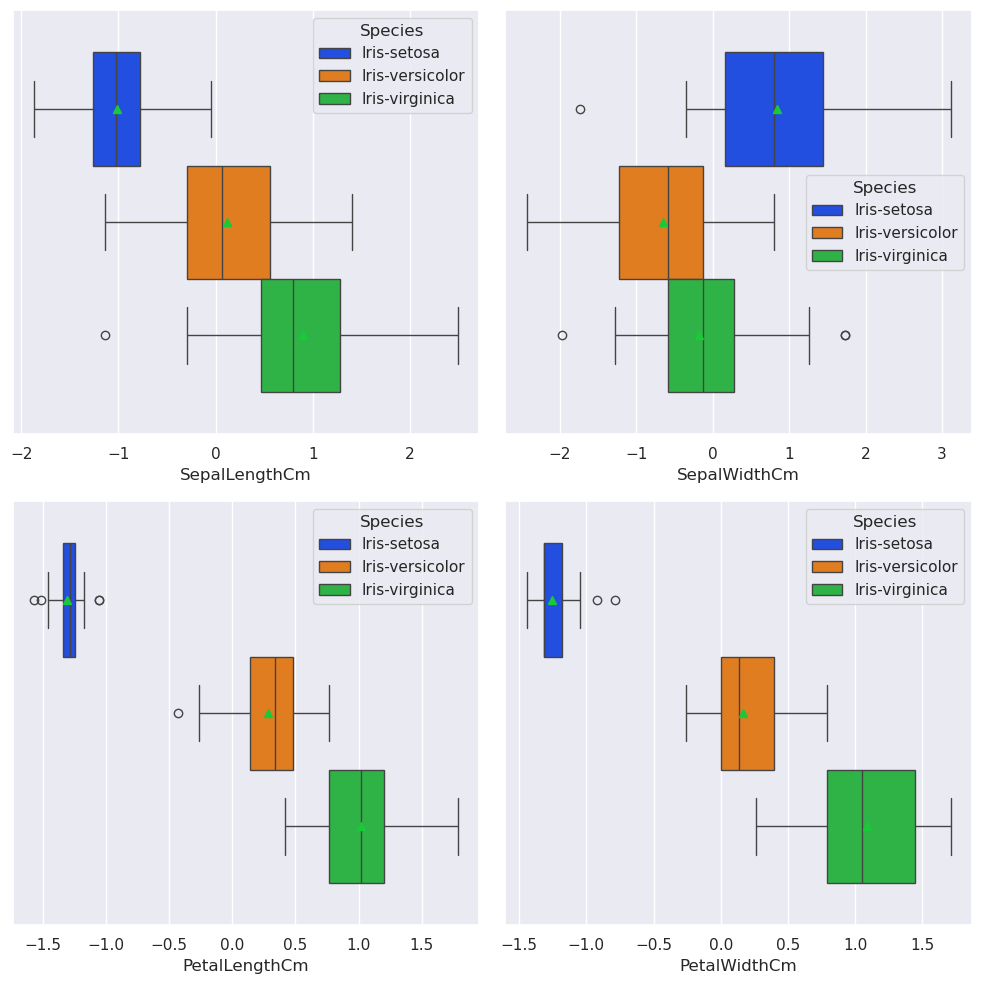

In [33]:
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

for ax, coluna in zip(axs.flatten(), X_scaled.columns):
    sns.boxplot(x=coluna, data=df_scaled, ax=ax, showmeans=True, hue="Species")

plt.tight_layout()
plt.show()